# CTG: exploração dos dados (T3)
Só o conjunto de treino. O teste só é aberto na T7.

In [21]:
# Célula 1 - imports e dados

import matplotlib.pyplot as plt
import numpy as np
from statstech.cluster import KMeans
from statstech.decomposition import PCA
from statstech.preprocessing import StandardScaler

from analysis.config import SEED, STYLE
from analysis.io import load_dataset
from analysis.report import save_figure, save_table

plt.style.use(STYLE)

CLASS_NAMES = ["Normal", "Suspeito", "Patológico"]
CLASS_COLORS = ["tab:blue", "tab:orange", "tab:red"]

d = load_dataset("ctg")
X, y, names = d["X_train"], d["y_train"], d["feature_names"]  # só o treino
idx = {name: i for i, name in enumerate(names)}
print(X.shape, np.bincount(y))  # esperado: (1755, 20) [1363 245 147]

(1755, 20) [1363  245  147]


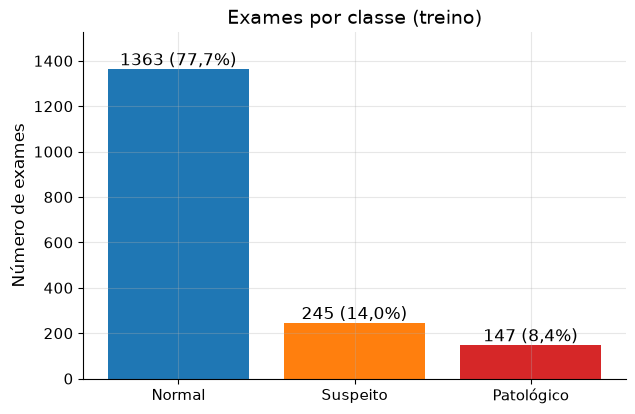

In [ ]:
# Célula 2 - gráfico de barras com contagem de exames por classe
# gera (ctg_classes.png)

counts = np.bincount(y)
percentages = counts / counts.sum() * 100
labels = [
    f"{count} ({pct:.1f}%)".replace(".", ",")
    for count, pct in zip(counts, percentages)
]

fig, ax = plt.subplots()
bars = ax.bar(CLASS_NAMES, counts, color=CLASS_COLORS)
ax.bar_label(bars, labels=labels)
ax.set_ylim(0, counts.max() * 1.12)
ax.set_ylabel("Número de exames")
ax.set_title("Exames por classe (treino)")
save_figure(fig, "ctg_classes")
plt.show()

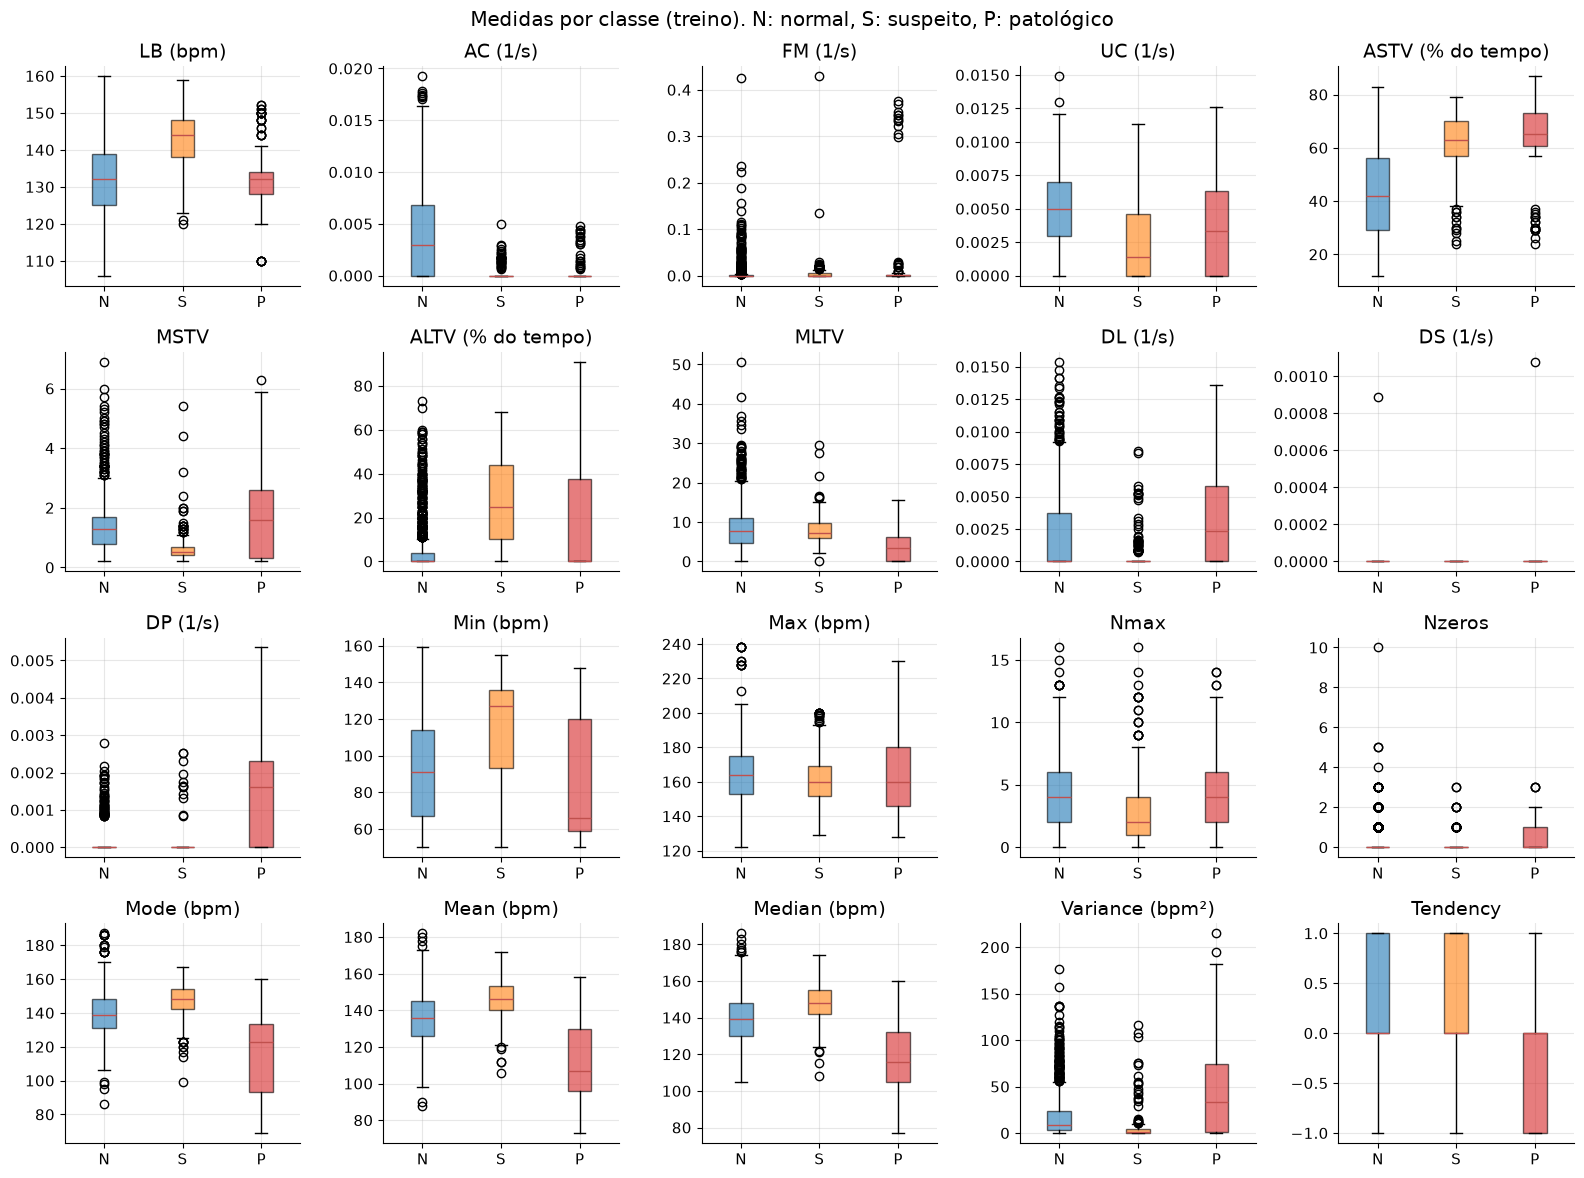

In [ ]:
# Célula 3 - boxplots das medidas por classe
# Gera (ctg_boxplots.png)

UNITS = {
    "LB": "bpm", "Min": "bpm", "Max": "bpm",
    "Mode": "bpm", "Mean": "bpm", "Median": "bpm",
    "Variance": "bpm²",
    "AC": "1/s", "FM": "1/s", "UC": "1/s",
    "DL": "1/s", "DS": "1/s", "DP": "1/s",
    "ASTV": "% do tempo", "ALTV": "% do tempo",
}

fig, axes = plt.subplots(4, 5, figsize=(16, 12))
for j, ax in enumerate(axes.flat):
    values_by_class = [X[y == k, j] for k in range(3)]
    box = ax.boxplot(values_by_class, patch_artist=True)
    for patch, color in zip(box["boxes"], CLASS_COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    unit = UNITS.get(names[j], "")
    ax.set_title(f"{names[j]} ({unit})" if unit else names[j])
    ax.set_xticks([1, 2, 3], ["N", "S", "P"])

fig.suptitle("Medidas por classe (treino). N: normal, S: suspeito, P: patológico")
fig.tight_layout()
save_figure(fig, "ctg_boxplots")
plt.show()

Célula 4 - medidas que separam as classes


In [25]:
# Célula 5 - fração de zeros por classe
# gera (ctg_fracao_zeros.csv)

# Boxplots de DS, DP, FM e Nzeros ficam colapsados em zero. Esta tabela mostra
# a fração de zeros por classe e confirma a variância nula do DS no suspeito.
rows = []
for name in ["FM", "DS", "DP", "Nzeros"]:
    zeros = [(X[y == k, idx[name]] == 0).mean() for k in range(3)]
    rows.append({"medida": name, **dict(zip(CLASS_NAMES, np.round(zeros, 3)))})
save_table(rows, "ctg_fracao_zeros")

ds = X[:, idx["DS"]]
for k, class_name in enumerate(CLASS_NAMES):
    n_nonzero = int((ds[y == k] != 0).sum())
    print(f"DS, {class_name}: {n_nonzero} linhas não nulas, "
          f"variância {ds[y == k].var():.2e}")

DS, Normal: 1 linhas não nulas, variância 5.81e-10
DS, Suspeito: 0 linhas não nulas, variância 0.00e+00
DS, Patológico: 1 linhas não nulas, variância 7.86e-09


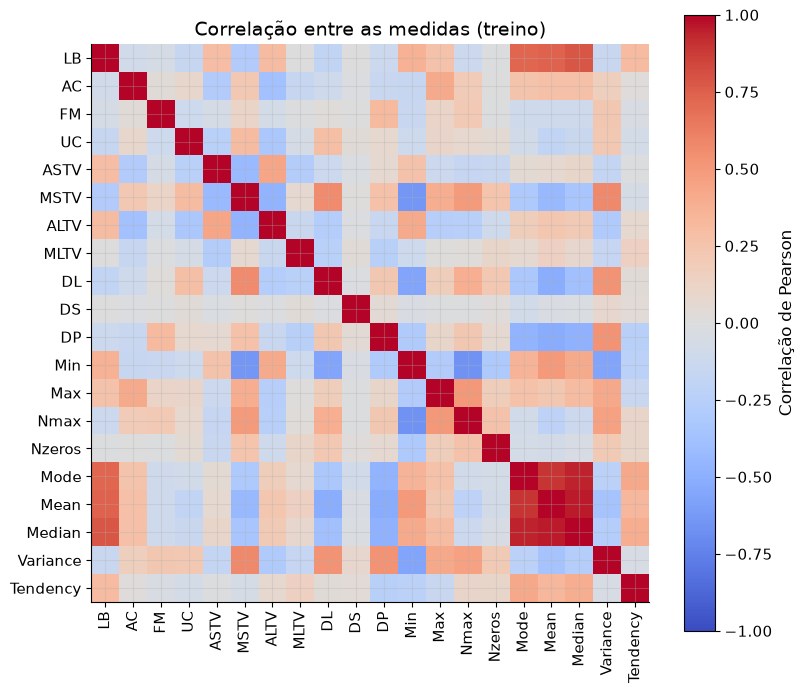

In [26]:
# Célula 6 - matriz de correlação
# gera (ctg_correlacao.png)

corr = np.corrcoef(X, rowvar=False)
assert corr.shape == (len(names), len(names))
assert not np.isnan(corr).any()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(names)), names, rotation=90)
ax.set_yticks(range(len(names)), names)
fig.colorbar(im, ax=ax, label="Correlação de Pearson")
ax.set_title("Correlação entre as medidas (treino)")
save_figure(fig, "ctg_correlacao")
plt.show()